# Numerical simulation for double-bracket quantum algorithms for quantum imaginary-time evolution (DB-QITE) using density matrix exponentiation (DME)

## 1. Initialization

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import sys
sys.path.append('..')
from functions.qite_gci import *
from functions.qite_dme import *
from functions.plot_bloch_sphere import *

# Plot config
plt.rcParams.update({
    'axes.labelsize': 16,
    'axes.titlesize': 16,
    'font.size': 16,
    'savefig.dpi': 75,
    'lines.linewidth': 2.0,
    'lines.markersize': 8,
    'legend.fontsize': 14,
    'legend.labelspacing': .3,
    'legend.columnspacing': .3,
    'legend.handletextpad': .1,
    'text.usetex': True,
    'font.family': "serif",
    'font.serif': "cm",
    'figure.figsize': [5, 3.5],
    'figure.autolayout': True
})

---
## 2. Run DB-QITE with DME

### 2.1 Find optimal s
Import the optimal s array generated in `find_optimal_s_dbqite.ipynb`

In [19]:
optimal_s_Mk = np.load('optimal_s_Mk.npy')

### 2.2 k = 1

This section shows **DB-QITE** results for different initial states, parameterized by recursion steps \(k\) and DME Trotter steps \(M\).

- The **x-axis** shows the fidelity of each initial state with the ground state. These initial states are prepared by applying \( RX(\theta) \) rotations to \(\ket{0}\), varying only the **latitude** on the Bloch sphere. This is because energy—relevant for state reset—depends on **latitude**, not longitude.
- The **y-axis** shows the fidelity with the ground state **after DB-QITE**. Higher values (closer to 1) indicate better reset performance.

#### Parameters

- `Ms = [1, 2, 50]`: List of \(M\) values representing DME memory (Trotter) steps.
- `k = 1`: Number of DB-QITE recursion iterations.

#### 1. Generate Initial States

- `thetas` is a linear space of 100 values from 0 to 1.
- `sigma_x` is the Pauli-X matrix.
- `psis` is a list of quantum states generated by evolving the state \(|1\rangle\) under the Pauli-X Hamiltonian:
  
  \[
  \ket{\psi(\theta)} = e^{-i \frac{\pi}{2} \theta \sigma_x} \ket{1}
  \]

#### 2. Run DB-QITE for Each M

- For each \(M \in \{1, 2, 50\}\), the DB-QITE energy is computed using the optimal step size \(s\) stored in `optimal_s_Mk`.
- Final fidelity is computed as:

  \[
  F = \frac{1 - E}{2}
  \]

  where \(E\) is the final energy returned by the DB-QITE routine (closer to 1 implies worse fidelity, so subtracting and scaling brings it back to fidelity-like form).


In [20]:
import numpy as np

def apply_depolarising_channel(psi, p):
    """
    Apply a single-qubit depolarising channel to pure state |psi⟩.
    """
    # Projector for |psi><psi|
    rho_pure = np.outer(psi, np.conj(psi))

    # Depolarising channel
    rho = (1 - p) * rho_pure + p * np.eye(2) / 2
    return rho

In [21]:
np.eye(2)

array([[1., 0.],
       [0., 1.]])

In [35]:
# Ms = [1, 2]
Ms=[1]
k = 1
p=0.3

# Initial state sweep
thetas = np.linspace(0, 1, 100)
sigma_x = np.array([[0, 1], [1, 0]])
psis = [expm(-1j * np.pi/2 * sigma_x * t) @ np.array([[0], [1]]) for t in thetas]
psis = np.asarray(psis)


# Baseline GCI energy results
res_init = [GCI(initial_psi, psi, 1, np.linspace(0.01, 1, 2)).execute_gci()[0][-1] for psi in psis]

# Run DB-QITE for each M with optimal s
dict_res_DBQITE = {}
for M in Ms:
    res_DBQITE = [GCI(QITE_dme_select_M(M), psi, None, optimal_s_Mk[M-1][:k]).execute_gci()[0][-1] for psi in psis]
    dict_res_DBQITE[f'k={k}, M={M}, s = {np.round(optimal_s_Mk[M-1][:k], 2)}'] = res_DBQITE

# Ms = [1]
# k = 2
# for M in Ms:
#     res_DBQITE = [GCI(QITE_dme_select_M(M), psi, None, optimal_s_Mk[M-1][:k]).execute_gci()[0][-1] for psi in psis]
#     dict_res_DBQITE[f'k={k}, M={M}, s = {np.round(optimal_s_Mk[M-1][:k], 2)}'] = res_DBQITE
    
# # Compute fidelities: (1 - E)/2
dict_fid_RGCI = {key: [(1 - E) / 2 for E in values] for key, values in dict_res_DBQITE.items()}
# # Initial state fidelities and RGCI outputs
# fidelities_original = [fidelity_with_0(x) for x in psis]
# fidelity = [(1 - E) / 2 for E in res_init]

0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of inter

In [36]:
# Ms = [1, 2]
Ms=[1]
k = 1
p=0.3

# Initial state sweep
thetas = np.linspace(0, 1, 100)
sigma_x = np.array([[0, 1], [1, 0]])
psis = [expm(-1j * np.pi/2 * sigma_x * t) @ np.array([[0], [1]]) for t in thetas]
psis = [apply_depolarising_channel(psi,p) for psi in psis]
psis = np.asarray(psis)


# Baseline GCI energy results
res_init = [GCI(initial_psi, psi, 1, np.linspace(0.01, 1, 2)).execute_gci()[0][-1] for psi in psis]

# Run DB-QITE for each M with optimal s

for M in Ms:
    res_DBQITE = [GCI(QITE_dme_select_M(M), psi, None, optimal_s_Mk[M-1][:k]).execute_gci()[0][-1] for psi in psis]
    dict_res_DBQITE[f'k={k}, M={M}, s = {np.round(optimal_s_Mk[M-1][:k], 2)},p={p}'] = res_DBQITE

# Ms = [1]
# k = 2
# for M in Ms:
#     res_DBQITE = [GCI(QITE_dme_select_M(M), psi, None, optimal_s_Mk[M-1][:k]).execute_gci()[0][-1] for psi in psis]
#     dict_res_DBQITE[f'k={k}, M={M}, s = {np.round(optimal_s_Mk[M-1][:k], 2)},p={p}'] = res_DBQITE
    
# Compute fidelities: (1 - E)/2
dict_fid_RGCI = {key: [(1 - E) / 2 for E in values] for key, values in dict_res_DBQITE.items()}

0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of inter

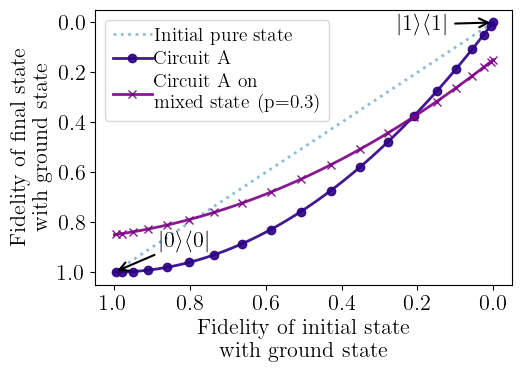

In [56]:
target_fidelity = 0.9

# Define reference state |0⟩⟨0|
state_0 = np.array([1, 0], dtype=complex)

# Fidelity with respect to |0⟩ for both pure and mixed states
def fidelity_with_0(state):
    return np.real(np.conj(state_0).T @ (state @ state.T.conj() if state.ndim == 2 and state.shape[1] == 1 else state) @ state_0)



# Plot setup
color = ['#2c0084', '#7a0085', '#006f7a', 'C0','#2c0084', '#7a0085', '#006f7a', 'C0']
markers = ['o','x','^','*','P','*','h']
max_ext_list = []
 
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.plot(fidelities_original, fidelity, label="Initial pure state", alpha=0.5, linestyle=':')

# # Highlight three specific points
# plt.plot(fidelities_original[70], fidelity[70], 'o', color='C2', markersize=15, zorder=0)
# plt.plot(fidelities_original[55], fidelity[55], 's', color='C1', markersize=15, zorder=0)
# plt.plot(fidelities_original[20], fidelity[20], 'd', color='C3', markersize=15, zorder=0)

# circuit_name = ['Circuit A', 'Circuit B', 'Circuit C',f'Circuit A (p={p})', f'Circuit B (p={p})', f'Circuit C (p={p})']
circuit_name = ['Circuit A',f'Circuit A on\nmixed state (p={p})']

# Plot each RGCI curve and draw vertical line at max excitation fidelity above target
for i, (key, value) in enumerate(dict_fid_RGCI.items()):
    # max_ext = max_excitation(fidelities_original, np.real(value), target_fidelity)
    # if max_ext: ax.axvline(x=max_ext, ymax=0.2, color=color[i], alpha=0.8, linestyle='--')
    # max_ext_list.append(max_ext)
    ax.plot(fidelities_original, value, label=circuit_name[i], color=color[i],
            marker=markers[i], markevery=5, markersize=6, alpha=0.9)

# Reverse axes: higher overlap → left/lower corner
plt.gca().invert_xaxis()
plt.gca().invert_yaxis()
# ax.axhline(y=target_fidelity, color='k', alpha=0.6, linestyle='--', label=f'Target F = {target_fidelity}')

# Labels and legend
ax.set_xlabel('Fidelity of initial state\nwith ground state')
ax.set_ylabel('Fidelity of final state\nwith ground state')
ax.legend()

# Annotate |1⟩ and |0⟩ 
ax.annotate(r'$|1\rangle\langle 1|$', xy=(fidelities_original[0], fidelity[0]), 
            xytext=(fidelities_original[0]+0.25, fidelity[0]+0.03), arrowprops=dict(arrowstyle='->', lw=1.5))
ax.annotate(r'$|0\rangle\langle 0|$', xy=(fidelities_original[-1], fidelity[-1]), 
            xytext=(fidelities_original[-1]-0.12, fidelity[-1]-0.1), arrowprops=dict(arrowstyle='->', lw=1.5))

plt.tight_layout()
plt.savefig(f'plots/QITE_DME_k_{k}_M_fidelity_final_vs_original.pdf')

# Report max fidelity locations
for M, max_val in zip(Ms, max_ext_list):
    print((M, np.round(max_val, 2)))

In [57]:
color = ['C0','#2c0084','#7a0085','#006f7a']

In [58]:
states_good = GCI(QITE_dme_select_M(1), psis[70], None, optimal_s_Mk[0][:1]).execute_gci()[-3]
states_mid = GCI(QITE_dme_select_M(1), psis[55], None, optimal_s_Mk[0][:2]).execute_gci()[-3]
states_bad = GCI(QITE_dme_select_M(2), psis[30], None, optimal_s_Mk[1][:2]).execute_gci()[-3]

texts = ['Initial state',r'$k=1$',r'$k=2$']

0.0 0.5570332883715823 (0.42392678099636694+0j)
-0.16044597838510152 0.16044598454317627 (0.5790698231733962+2.004039059112588e-18j)


c:\Python\Lib\site-packages\mpl_toolkits\mplot3d\axes3d.py:3305: ComplexWarning: Casting complex values to real discards the imaginary part
  UVW = np.column_stack(input_args[3:]).astype(float)


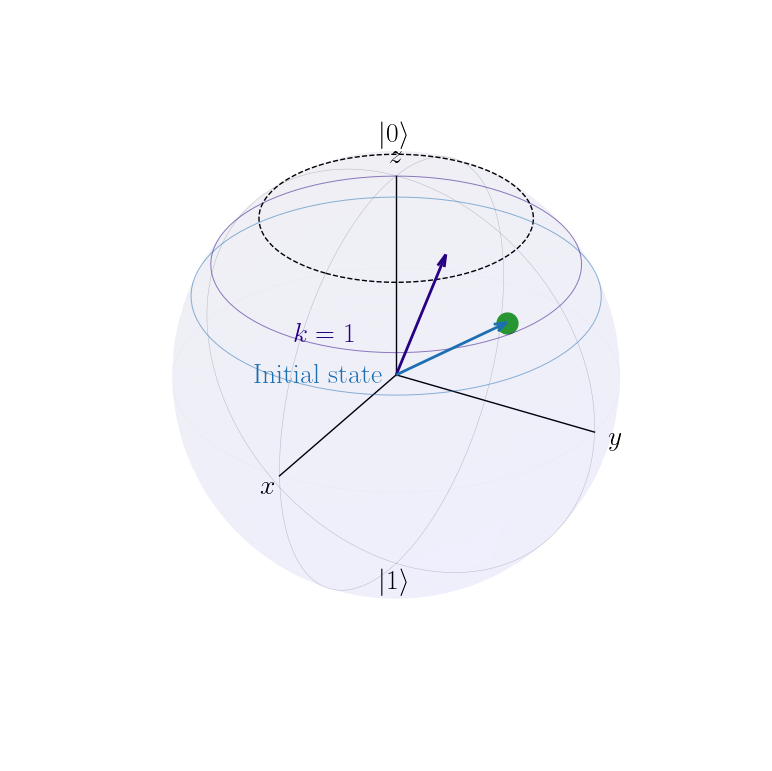

In [59]:
# Create the plot
ax = plot_bloch_sphere()

fidelity = 0.9
theta = 2 * np.arccos(np.sqrt(fidelity))
u = np.linspace(0, 2 * np.pi, 100)
x_latitude = np.outer(np.cos(u), np.sin(theta))
y_latitude = np.outer(np.sin(u), np.sin(theta))
z_latitude = np.outer(np.ones(np.size(u)), np.cos(theta))
ax.plot(x_latitude, y_latitude, z_latitude, color='k', lw=1, alpha=1,linestyle='--')

# Plot the Bloch sphere with vector
i=0
for state in states_good:
    if i==0:
        ax = plot_bloch_vector(state,ax,color=color[i],text=texts[i],marker='o',marker_color='C2')
    else:
        ax = plot_bloch_vector(state,ax,color=color[i],text=texts[i])
    i+=1
# Show the plot
plt.savefig(f'plots/bloch_good.pdf', bbox_inches="tight", pad_inches=-1.1)
plt.show()